# Feature selection

This notebook decides which features go into `train.ipynb`. It is not part of `main.py`. I ran it to make the choice, and `train.ipynb` only builds the features that came out of it.

The plan:

1. Build 13 candidate feature groups, all known at the moment the order is placed.
2. Split by time like in `train.ipynb` and drop the test months straight away, so no decision here uses them.
3. Look at the data to decide how to prepare each column.
4. Remove groups one at a time while validation does not get worse (backward elimination).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SAMPLED = Path("data/sampled")
orders = pd.read_csv(SAMPLED / "orders.csv", parse_dates=["order_purchase_timestamp", "order_estimated_delivery_date"])
items = pd.read_csv(SAMPLED / "order_items.csv")
payments = pd.read_csv(SAMPLED / "order_payments.csv")
customers = pd.read_csv(SAMPLED / "customers.csv")
products = pd.read_csv(SAMPLED / "products.csv")
sellers = pd.read_csv(SAMPLED / "sellers.csv")
geo = pd.read_csv(SAMPLED / "geolocation.csv").set_index("geolocation_zip_code_prefix")

## 1. Candidate features

One row per order. Every candidate is something we know when the customer clicks "buy". I left out things that only exist later, like the payment approval time, the date the carrier picked up the parcel, or the review.

`GROUPS` lists which columns belong to which idea, so a whole idea is added or removed at once (product size is two columns, weight and volume).

Some columns get a fixed reshape (log or a cap). Section 3 shows why. Since these are formulas and not learned from the data, doing them before the split is fine.

In [2]:
def haversine_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))


o = orders.set_index("order_id")
df = pd.DataFrame({"purchase_ts": o["order_purchase_timestamp"], "late": o["late"].astype(int)})

# one row per item, with product, seller and customer details
it = (items.merge(orders[["order_id", "customer_id"]], on="order_id")
           .merge(customers, on="customer_id")
           .merge(products, on="product_id", how="left")
           .merge(sellers, on="seller_id", how="left"))
seller_xy = geo.reindex(it["seller_zip_code_prefix"])
customer_xy = geo.reindex(it["customer_zip_code_prefix"])
it["distance_km"] = haversine_km(seller_xy["geolocation_lat"].values, seller_xy["geolocation_lng"].values,
                                 customer_xy["geolocation_lat"].values, customer_xy["geolocation_lng"].values)
it["volume_cm3"] = it["product_length_cm"] * it["product_height_cm"] * it["product_width_cm"]
it["same_state"] = it["seller_state"] == it["customer_state"]
per_order = it.groupby("order_id")

# raw versions, only used to check skew and to test whether the reshaping helps
raw = pd.DataFrame({
    "n_items": per_order.size(),
    "n_sellers": per_order["seller_id"].nunique(),
    "distance_km": per_order["distance_km"].mean(),
    "freight_total": per_order["freight_value"].sum(),
    "price_total": per_order["price"].sum(),
})

df["n_items"] = raw["n_items"].clip(upper=5)
df["n_sellers"] = raw["n_sellers"].clip(upper=3)
df["promised_days"] = (o["order_estimated_delivery_date"] - o["order_purchase_timestamp"]) / pd.Timedelta(days=1)
df["customer_state"] = o["customer_id"].map(customers.set_index("customer_id")["customer_state"])
df["same_state_share"] = per_order["same_state"].mean()
df["log_distance_km"] = np.log1p(raw["distance_km"])
df["log_weight_g"] = np.log1p(per_order["product_weight_g"].sum(min_count=1))   # min_count=1: all missing stays missing
df["log_volume_cm3"] = np.log1p(per_order["volume_cm3"].sum(min_count=1))
df["log_freight"] = np.log1p(raw["freight_total"])
df["log_price"] = np.log1p(raw["price_total"])
biggest_payment = payments.sort_values("payment_value", ascending=False).drop_duplicates("order_id")
df["payment_type"] = biggest_payment.set_index("order_id")["payment_type"]
df["purchase_month"] = df["purchase_ts"].dt.month
df["purchase_dow"] = df["purchase_ts"].dt.dayofweek
df["purchase_hour"] = df["purchase_ts"].dt.hour

GROUPS = {
    "n_items": ["n_items"],
    "n_sellers": ["n_sellers"],
    "promised_days": ["promised_days"],
    "customer_state": ["customer_state"],
    "same_state": ["same_state_share"],
    "distance": ["log_distance_km"],
    "product_size": ["log_weight_g", "log_volume_cm3"],
    "freight": ["log_freight"],
    "price": ["log_price"],
    "payment_type": ["payment_type"],
    "month": ["purchase_month"],
    "day_of_week": ["purchase_dow"],
    "hour": ["purchase_hour"],
}
# labels, not amounts: one-hot encoded. Everything else is numeric.
CATEGORICAL = ["customer_state", "payment_type", "purchase_month", "purchase_dow", "purchase_hour"]

df = df.join(raw.add_suffix("_raw"))
print(df.shape)
df.head()

(20001, 21)


,purchase_ts,late,n_items,n_sellers,promised_days,customer_state,same_state_share,log_distance_km,log_weight_g,log_volume_cm3,...,log_price,payment_type,purchase_month,purchase_dow,purchase_hour,n_items_raw,n_sellers_raw,distance_km_raw,freight_total_raw,price_total_raw
order_id,,,,,,,,,,,,,,,,,,,,,
597bd074d7874048131c67581f0556d4,2017-01-31 11:54:14,0,1,1,36.504005,SP,0.0,5.917491,6.473891,8.378161,...,4.109233,boleto,1,1,11,1,1,370.478622,14.59,59.90
944f618b790d6d01c2c78750fc0f700a,2017-01-17 15:01:33,0,2,1,40.373924,MG,0.0,5.913941,6.415097,8.437934,...,3.908015,credit_card,1,1,15,2,1,369.161946,29.04,48.80
dba1b6fd34a7fd5961e829fa902ca702,2017-01-28 23:29:12,0,1,1,45.021389,SP,1.0,4.900311,5.303305,7.117206,...,3.783962,credit_card,1,5,23,1,1,133.331536,18.00,42.99
24e1c731364b64c76d98e985bfdbef77,2017-01-17 20:38:15,0,1,1,40.140104,PR,0.0,5.883346,8.006701,9.262079,...,5.062595,credit_card,1,1,20,1,1,358.008392,18.85,157.00
ae162713f33901220faa2a22c2bdba45,2017-01-31 14:38:41,0,3,1,36.389803,SP,1.0,4.442867,8.962007,12.257721,...,5.885548,boleto,1,1,14,3,1,84.018343,34.35,358.80


## 2. Time split, then drop test

Same rule as `train.ipynb`: test is the last 3 months, validation the 2 months before, train everything earlier.

In [3]:
last_month = df["purchase_ts"].max().to_period("M")
test_start = (last_month - 2).start_time
val_start = (last_month - 4).start_time

df = df[df["purchase_ts"] < test_start]   # test months removed here
train, val = df[df["purchase_ts"] < val_start], df[df["purchase_ts"] >= val_start]

print(f"train {len(train)} orders, late rate {train['late'].mean():.3f}")
print(f"val   {len(val)} orders, late rate {val['late'].mean():.3f} ({int(val['late'].sum())} late orders)")

train 13315 orders, late rate 0.080
val   2817 orders, late rate 0.055 (156 late orders)


## 3. Looking at the data

### Late rate over time

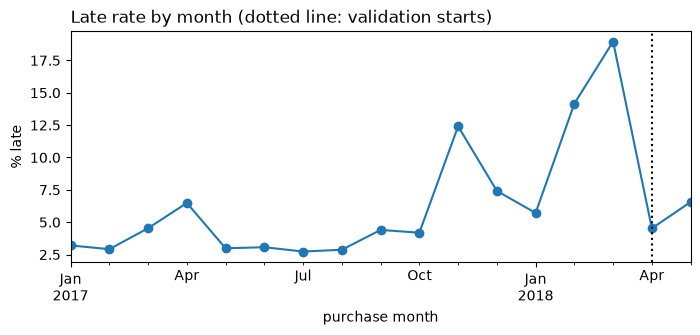

In [4]:
monthly = df.groupby(df["purchase_ts"].dt.to_period("M").dt.to_timestamp())["late"].mean() * 100
ax = monthly.plot(marker="o", figsize=(8, 3), ylabel="% late", xlabel="purchase month")
ax.axvline(val_start, color="k", ls=":")
ax.set_title("Late rate by month (dotted line: validation starts)", loc="left")
plt.show()

The late rate is low in most of 2017 and then jumps in November 2017 and February to March 2018. So the process changes over time, which is why I split by time.

It also made me suspicious of the month feature. With about 15 months of training data, each month value shows up only once or twice, so "month" mostly says which point in time an order is from. The model could learn that February is bad just because February 2018 was. I test this in section 4 instead of guessing.

### Missing values and skew (train only)

In [5]:
print("missing values:", train[[c for g in GROUPS.values() for c in g]].isna().sum()[lambda s: s > 0].to_dict())

pairs = [("n_items_raw", "n_items"), ("n_sellers_raw", "n_sellers"), ("distance_km_raw", "log_distance_km"),
         ("freight_total_raw", "log_freight"), ("price_total_raw", "log_price")]
pd.DataFrame({"skew raw": [train[a].skew() for a, b in pairs],
              "skew after log or cap": [train[b].skew() for a, b in pairs]},
             index=[b for a, b in pairs]).round(2)

missing values: {'log_distance_km': 67, 'log_weight_g': 4, 'log_volume_cm3': 4}


,skew raw,skew after log or cap
n_items,8.47,4.77
n_sellers,12.13,10.26
log_distance_km,1.64,-1.11
log_freight,7.94,1.21
log_price,7.91,0.27


Very few values are missing (distance where the zip code has no coordinates, and a few products without weight or size), so the median is enough to fill them.

Freight, price and distance have long right tails: a few huge values would stretch the scale after standardising. `log1p` pulls them in. The counts are almost always 1, so a log does not help much there. I cap them instead (5 items, 3 sellers) so the rare big orders do not stand out.

## 4. Testing feature groups

Every test fits the same pipeline (median fill, scaling, one-hot, logistic regression) on train and scores it on validation. The main score is log loss: lower is better. With no features at all the model predicts the train late rate for everyone, and that is the number to beat.

In [6]:
def make_pipeline(cols):
    num = [c for c in cols if c not in CATEGORICAL]
    cat = [c for c in cols if c in CATEGORICAL]
    parts = []
    if num:
        parts.append(("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False), cat))
    return Pipeline([("pre", ColumnTransformer(parts)), ("lr", LogisticRegression(max_iter=3000))])


def fit_score(cols):
    if not cols:   # no features: predict the train late rate for everyone
        p = np.full(len(val), train["late"].mean())
    else:
        p = make_pipeline(cols).fit(train[cols], train["late"]).predict_proba(val[cols])[:, 1]
    return {"log_loss": log_loss(val["late"], p),
            "roc_auc": roc_auc_score(val["late"], p),
            "pr_auc": average_precision_score(val["late"], p)}


def cols_of(groups):
    return [c for g in groups for c in GROUPS[g]]


baseline = fit_score([])
print("no features:", {k: round(v, 4) for k, v in baseline.items()})

no features: {'log_loss': 0.2186, 'roc_auc': 0.5, 'pr_auc': 0.0554}


### Each group on its own

`gain` is how much lower the validation log loss is than with no features. Negative means the group alone is worse than nothing.

In [7]:
solo = pd.DataFrame({g: fit_score(cols_of([g])) for g in GROUPS}).T
solo.insert(0, "gain", baseline["log_loss"] - solo["log_loss"])
solo.drop(columns="log_loss").sort_values("roc_auc", ascending=False).round(4)

,gain,roc_auc,pr_auc
distance,0.0078,0.6572,0.1347
customer_state,0.0065,0.6210,0.0770
freight,0.0034,0.6005,0.0801
same_state,0.0046,0.5886,0.0672
promised_days,0.0002,0.5408,0.0694
price,0.0001,0.5292,0.0674
product_size,0.0002,0.5196,0.0617
day_of_week,0.0003,0.5153,0.0581
n_items,0.0002,0.5095,0.0564
n_sellers,0.0006,0.5085,0.0563


Distance and state carry the most on their own. Month is clearly worse than nothing, which fits what I suspected in section 3. Hour and payment type are slightly worse than nothing too. I don't drop anything based on this table, because a feature that is weak alone can still help together with others.

### Backward elimination

Start with all 13 groups. In each round, try removing each group and refit. Remove the one the model misses least, as long as validation log loss does not get worse by more than 0.0005. Stop when every removal would cost more than that.

Validation has only 156 late orders, so differences smaller than about 0.0005 are noise. When two models are that close I prefer the one with fewer features.

In [8]:
TOLERANCE = 0.0005

kept = list(GROUPS)
current = fit_score(cols_of(kept))["log_loss"]
steps = [{"removed": "(nothing, all 13 groups)", "val log loss": current, "change": 0.0}]

while len(kept) > 1:
    trial = {g: fit_score(cols_of([k for k in kept if k != g]))["log_loss"] for g in kept}
    g_drop = min(trial, key=trial.get)
    change = trial[g_drop] - current
    if change > TOLERANCE:
        break
    kept.remove(g_drop)
    current = trial[g_drop]
    steps.append({"removed": g_drop, "val log loss": current, "change": change})

SELECTED = kept
print("kept:", SELECTED)
pd.DataFrame(steps).round(4)

kept: ['n_sellers', 'promised_days', 'customer_state', 'distance', 'freight']


,removed,val log loss,change
0,"(nothing, all 13 groups)",0.2019,0.0000
1,month,0.1959,-0.0060
2,hour,0.1955,-0.0004
3,payment_type,0.1952,-0.0003
4,price,0.1951,-0.0000
5,product_size,0.1952,0.0001
6,n_items,0.1954,0.0003
7,day_of_week,0.1958,0.0003
8,same_state,0.1962,0.0004


Month goes first and gives by far the biggest improvement. Hour, payment type and price were adding noise too. The later removals make validation very slightly worse, but each one stays within the tolerance, so I keep the simpler model. Same state was the closest call: removing it cost 0.0004, just under the tolerance, probably because distance already carries most of that information.

### How much each kept group matters

Remove one kept group at a time and see how much worse validation gets.

In [9]:
final = fit_score(cols_of(SELECTED))
print("selected groups:", {k: round(v, 4) for k, v in final.items()})

rows = {}
for g in SELECTED:
    r = fit_score(cols_of([k for k in SELECTED if k != g]))
    rows[g] = {"log loss gets worse by": r["log_loss"] - final["log_loss"], "roc auc without it": r["roc_auc"]}
pd.DataFrame(rows).T.sort_values("log loss gets worse by", ascending=False).round(4)

selected groups: {'log_loss': 0.1962, 'roc_auc': 0.7555, 'pr_auc': 0.1625}


,log loss gets worse by,roc auc without it
promised_days,0.0137,0.6466
customer_state,0.0050,0.7328
distance,0.0045,0.7318
freight,0.0011,0.7488
n_sellers,0.0007,0.7519


Promised delivery time matters most, even though it was weak on its own. A longer promise is partly a longer distance, so alone it mixes two things. With distance in the model it can show the slack the customer was given.

### Did the log and the caps help?

Same selected groups, with the raw columns instead of the reshaped ones.

In [10]:
raw_version = {"log_distance_km": "distance_km_raw", "log_freight": "freight_total_raw", "n_sellers": "n_sellers_raw"}
raw_cols = [raw_version.get(c, c) for c in cols_of(SELECTED)]
pd.DataFrame({"raw columns": fit_score(raw_cols), "log and caps": final}).T.round(4)

,log_loss,roc_auc,pr_auc
raw columns,0.1977,0.7540,0.1641
log and caps,0.1962,0.7555,0.1625


## Result

`train.ipynb` builds these five groups: promised_days, customer_state, distance (log), freight (log) and n_sellers (capped at 3). If I change the selection here, I also have to change the feature cell in `train.ipynb`.

In [11]:
SELECTED

['n_sellers', 'promised_days', 'customer_state', 'distance', 'freight']